# Data visualisation et analyse de cohortes e-commerce - Use case

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## USE CASE : Analyse de cohortes

**_Contexte_**

La plateforme e-commerce Olist connecte les propriétaires de petits business brésiliens (les vendeurs) avec des consommateurs partout au Brésil. Comprendre ce qui pousse les vendeurs à continuer d'utiliser la plateforme une fois qu'ils ont effectué leur première vente est une question essentielle pour Olist !

L'analyse de cohortes vise à séparer les individus en "cohortes" regroupées selon une caractéristique commune, puis étudier l'évolution de ces cohortes au cours du temps. Exemple : étudier l'impact d'une campagne marketing sur différence cohortes, analyser le taux d'attrition des cohortes, etc.

---

**_Mission_**

**Olist t'a engagé comme Data Analyst pour que réaliser une analyse de cohortes sur leurs données 2017-2018.**

Ici, les clients d'Olist sont les vendeurs du site. Il s'agira de les répartir en cohortes correspondant au mois de leur première vente. Il ne s'agit pas tout à fait d'une analyse de cohortes classique : ici, l'objectif sera de suivre la **proportion de vendeurs de chaque cohorte qui continue à utiliser la plateforme** les mois suivant leur première vente.

---

**_Données_**

Les données à utiliser sont disponibles sur la plateforme ainsi que sur [Kaggle](https://www.kaggle.com/olistbr/brazilian-ecommerce). Nous utiliserons les tables  `olist_sellers_dataset`, `olist_orders_dataset` et `olist_order_items_dataset`.
N'hésitez pas à vous aider de la documentation sur les tables disponible sur Kaggle : [lien](https://www.kaggle.com/olistbr/brazilian-ecommerce).

###  1. Fusionner les tables à analyser

Pour cette analyse, nous n'aurons besoin que de 2 variables : les IDs des vendeurs dans `olist_sellers_dataset` et la date de chaque vente (`order_purchase_timestamp`) dans `olist_orders_dataset`. 

**Fusionner les tables et ne conserver que les 2 colonnes pertinentes.**

_Indice : pour connecter les deux tables, il est indispensable d'utiliser `olist_order_items_dataset` comme intermédiaire (avec `order_id`)._

In [133]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [156]:
np.__version__

'1.26.4'

In [158]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
order_items = pd.read_csv('/Users/LENOVO/Downloads/FTD - J24 - PYTHON - 1. Cas pratique - olist_order_items_dataset.csv')
sellers = pd.read_csv('/Users/LENOVO/Downloads/FTD - J24 - PYTHON - 1. Cas pratique - olist_sellers_dataset.csv')
orders = pd.read_csv('/Users/LENOVO/Downloads/FTD - J24 - PYTHON - 1. Cas pratique - olist_orders_dataset.csv')

In [ ]:
order_sellers = orders.merge(order_items,on="order_id").merge(sellers,on="seller_id")

In [135]:
df = order_sellers [['seller_id','order_purchase_timestamp']]

###  2. Convertir la colonne de dates au bon type, et conserver uniquement les données de Jan 2017 à Sept 2018

_Indice :  il est possible (mais optionnel) d'utiliser les méthodes `df.assign()` et `df.query()`. `df.assign()` permet de créer une nouvelle colonne à partir d'une fonction lambda. `df.query()` permet de filtrer un dataframe selon la date. Ces méthodes sont "bonus", elles permettent d'être plus concis mais ne sont pas du tout obligatoires._

In [136]:
# Méthode classique
df['date'] = pd.to_datetime(df['order_purchase_timestamp'])
df = df.drop('order_purchase_timestamp',axis=1)
df = df[ (df['date'] >='2017') & (df['date'] <= '09-2018') ]

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_25584\3575382164.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['date'] = pd.to_datetime(df['order_purchase_timestamp'])


In [107]:
# Méthode plus simple
df = (df
      .assign(date = lambda x:pd.to_datetime(x.date)) #permet d'ajouter une colonne
      .query('date >= "2017-01-01" & date < "2018-09-01" ') #équivalent filtre between
     )

### 3. Constituer les cohortes selon le mois de première vente (1 cohorte par mois)

Pour créer les cohortes, commencer par extraire le mois de vente à partir des dates complètes.

Ensuite, ordonner les données selon le mois de vente et supprimer les doublons dans la colonne `seller_id` (afin de ne conserver que la première apparition de chaque vendeur).

_Hint: Pour extraire le mois, on peut utiliser la méthode `df['col'].dt.to_period('M')`._

In [138]:
#Copie de df avant modification
seller_cohort = df.copy()

# tri et drop_duplicates pour conserver seulement la 1ère vente
seller_cohort = seller_cohort.sort_values("date",ascending = True)
seller_cohort = seller_cohort.drop_duplicates(subset='seller_id',keep='first')

#extraction du mois (nom de cohorte)
seller_cohort ['cohort'] = seller_cohort['date'].dt.to_period('M')
seller_cohort = seller_cohort.drop('date', axis = 1)
seller_cohort

,seller_id,cohort
89123,48efc9d94a9834137efd9ea76b065a38,2017-01
7318,8f119a0aee85c0c8fc534629734e94fd,2017-01
6757,b14db04aa7881970e83ffa9426897925,2017-01
27210,46dc3b2cc0980fb8ec44634e21d2718e,2017-01
107046,b2ba3715d723d245138f291a6fe42594,2017-01
...,...,...
79587,26e2e5033827d2ba53929f43e03d8ffe,2018-08
1181,b76f4d90e85657a240495c876313adc5,2018-08
11620,e8ff5a6ceb895583033fc2a0f314e3c2,2018-08
90181,3296662b1331dea51e744505065ae889,2018-08


In [127]:
#Méthode plus simple
seller_cohort = (df
                 .assign( cohort = lambda x : x['date'].dt.to_period('M') ) #ajout colonne mois nommé cohort
                 .sort_values('date')  #tri
                 .drop_duplicates(subset='seller_id',keep='first') #suppression des doublons en gardant la première ligne de chaque seller_id (càd première date suite au tri juste avant) 
                 .reset_index()
                 .loc[:,['seller_id','cohort'] ] #colonnes conservées grâce à loc. Pas besoin de suppresion
                )
                

###  4. Visualiser le nombre de vendeurs dans chaque cohorte grâce à un diagramme en bâtons

Avant de continuer l'analyse, nous allons visualiser nos données - en particulier, nous aimerions avoir une idée de la taille de chaque cohorte. Compter le nombre de vendeurs uniques dans chaque cohorte, puis utiliser seaborn pour créer un bar chart.


_Indice : souvenez-vous de la fonction `sns.catplot()` !_

In [139]:
#Cohort size / Méthode classique

size_cohorts = (seller_cohort
                .groupby('cohort')['seller_id']
                .nunique()
                .reset_index()
               )

In [ ]:
#Cohort size / Méthode simple 1
size_cohorts = seller_cohort.value_counts(subset='cohort')

#Cohort size / Méthode simple 2 
size_cohorts = seller_cohort['cohort'].value_counts()

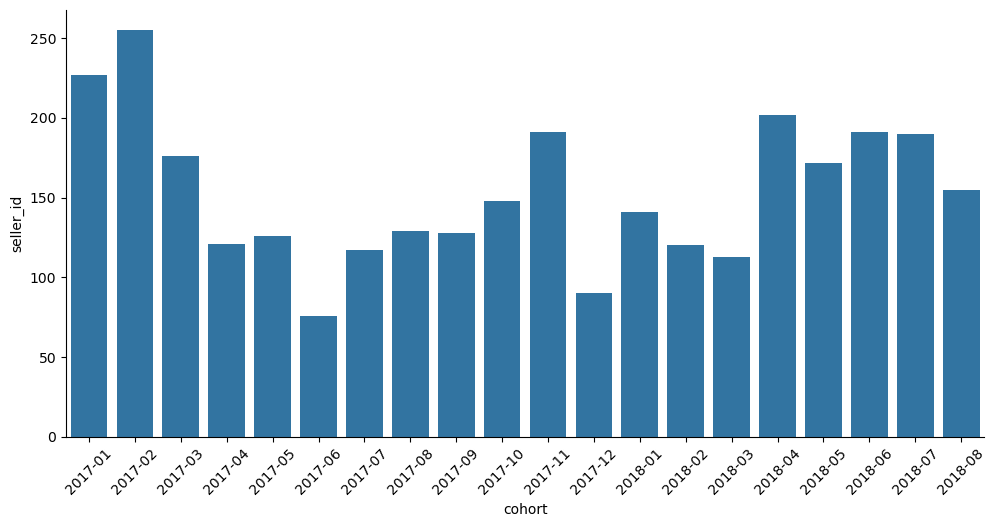

In [150]:
sns.catplot(data=size_cohorts,x='cohort',y='seller_id',kind='bar',aspect = 2)
plt.xticks(rotation=45);

On observe une certaine variabilité dans le nombre de nouveaux vendeurs par mois, mais aucun effet saisonnier ne semble évident. Etudions l'attrition de ces cohortes.

### 5. Pour chaque vendeur, calculer la différence entre chacune de ses ventes et sa cohorte (mois de première vente)

Fusionner la table contenant les noms de cohortes (question précédente) avec la table initiale (contenant toutes les ventes). 

Il est maintenant possible de calculer la différence (en mois) entre la date de chaque vente et la cohorte du vendeur (mois de première vente). Vous pourrez appeler cette différence `delta`.

In [152]:
#Méthode classique
dif_seller_cohort = df.merge(seller_cohort,on="seller_id") #fusion des deux tables
dif_seller_cohort['date'] = dif_seller_cohort['date'].dt.to_period('M') #conversion de la colonne date en 'année-mois'
dif_seller_cohort ['delta'] = dif_seller_cohort['date'].astype('int64') - dif_seller_cohort ['cohort'].astype('int64') #calcul de la différence des mois. important : convertir les mois en nombre entier
dif_seller_cohort

In [167]:
#Méthode plus courte
cohort_df = (df.merge(seller_cohort,on="seller_id")
             .assign(date_of_sale = lambda x: x.date.dt.to_period('M'), #lecture : pour chaque élément dans la colonne ajoutée 'date', convertir en format 'année-mois' puis l'intégrer dans la nouvelle colonne 'date_of_sale' 
                     delta = lambda x: (x.date_of_sale - x.cohort).apply(lambda x: x.n) ) # n permet ici de convertir en nombre entier. 
             .loc[:, ['seller_id','cohort','date_of_sale','delta'] ]
            )
cohort_df.head(3)

,seller_id,cohort,date_of_sale,delta
0,3504c0cb71d7fa48d967e0e4c94d59d9,2017-07,2017-10,3
1,289cdb325fb7e7f891c38608bf9e0962,2018-02,2018-07,5
2,4869f7a5dfa277a7dca6462dcf3b52b2,2017-03,2018-08,17


###  6. Etude de l'attrition des vendeurs (churn)

Pour chaque cohorte, compter le nombre de vendeurs uniques par delta. 

Convertir ce nombre pour l'exprimer en pourcentage de la taille de la cohorte.

Ces calculs nous permettent d'observer quelle proportion de chaque cohorte continue de réaliser des ventes au fil du temps.

_Indices : il faudra d'abord grouper votre table par cohorte et par delta pour obtenir le nombre de vendeurs uniques par cohorte et par delta.
Ensuite, on pourra fusionner cette table avec les totaux calculés dans la question précédente, afin de calculer les pourcentages par rapport au total de chaque cohorte._

In [198]:
# Méthode 1 
churn = cohort_df.groupby(['cohort','delta'])['seller_id'].nunique().reset_index(name="nb_seller") #création table seller unique groupé par cohort puis delta
churn = churn.merge(size_cohorts,on="cohort") #fusion avec la table size_cohorts pour récupérer le total des sellers par mois
churn['proportion'] = (churn['nb_seller'] / churn['seller_id']) * 100 #calcul des proportions
churn = churn.drop(columns=['nb_seller','seller_id']) #suppression des colonnes dont nous n'avons plus besoin
churn

### 1.1.7. 7. Pivoter la table

Utiliser df.pivot() (ou df.pivot_table) pour obtenir une table avec le valeurs de delta en colonnes, les différentes cohortes en lignes et les proportions calculées comme valeurs


In [207]:
cohort_pivot = churn.pivot(columns ='delta',index='cohort',values='proportion') 
cohort_pivot

delta,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
cohort,,,,,,,,,,,,,,,,,,,,
2017-01,100.0,75.770925,73.568282,63.436123,66.079295,62.114537,55.947137,60.792952,55.506608,55.947137,54.625551,48.458150,50.660793,47.577093,48.458150,45.374449,38.766520,38.766520,35.682819,39.207048
2017-02,100.0,61.176471,54.509804,56.470588,45.098039,48.627451,47.450980,42.352941,41.960784,41.568627,41.960784,36.862745,35.686275,35.294118,37.254902,29.411765,30.980392,28.627451,25.882353,NaN
2017-03,100.0,57.954545,54.545455,49.431818,46.022727,48.295455,44.886364,40.909091,48.295455,36.931818,39.772727,32.954545,34.090909,30.681818,29.545455,29.545455,26.136364,27.840909,NaN,NaN
2017-04,100.0,55.371901,47.107438,51.239669,49.586777,44.628099,38.016529,47.107438,39.669421,38.842975,32.231405,33.884298,32.231405,30.578512,25.619835,28.925620,23.140496,NaN,NaN,NaN
2017-05,100.0,50.000000,50.000000,51.587302,46.825397,42.857143,43.650794,37.301587,39.682540,40.476190,35.714286,31.746032,27.777778,23.809524,27.777778,20.634921,NaN,NaN,NaN,NaN
2017-06,100.0,42.105263,40.789474,47.368421,31.578947,38.157895,36.842105,32.894737,27.631579,28.947368,27.631579,26.315789,21.052632,22.368421,21.052632,NaN,NaN,NaN,NaN,NaN
2017-07,100.0,67.521368,60.683761,59.829060,67.521368,59.829060,56.410256,52.991453,52.136752,52.136752,49.572650,49.572650,44.444444,47.863248,NaN,NaN,NaN,NaN,NaN,NaN
2017-08,100.0,54.263566,46.511628,55.038760,42.635659,44.186047,49.612403,42.635659,40.310078,37.984496,37.209302,31.782946,34.883721,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09,100.0,53.125000,54.687500,46.875000,50.000000,40.625000,44.531250,40.625000,40.625000,33.593750,31.250000,33.593750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


###  8. Visualiser les cohortes finales et les taux d'attrition grâce à une heatmap

_Indices : vous pourrez utiliser `plt.figure(figsize=(12, 8))` en première ligne de votre cellule pour ajuster la taille du graphique. Vous pourrez également ajouter dans la fonction `sns.heatmap()` les arguments : `cmap='crest', annot=True, fmt='.0f'`, pour un résultat plus esthétique !_

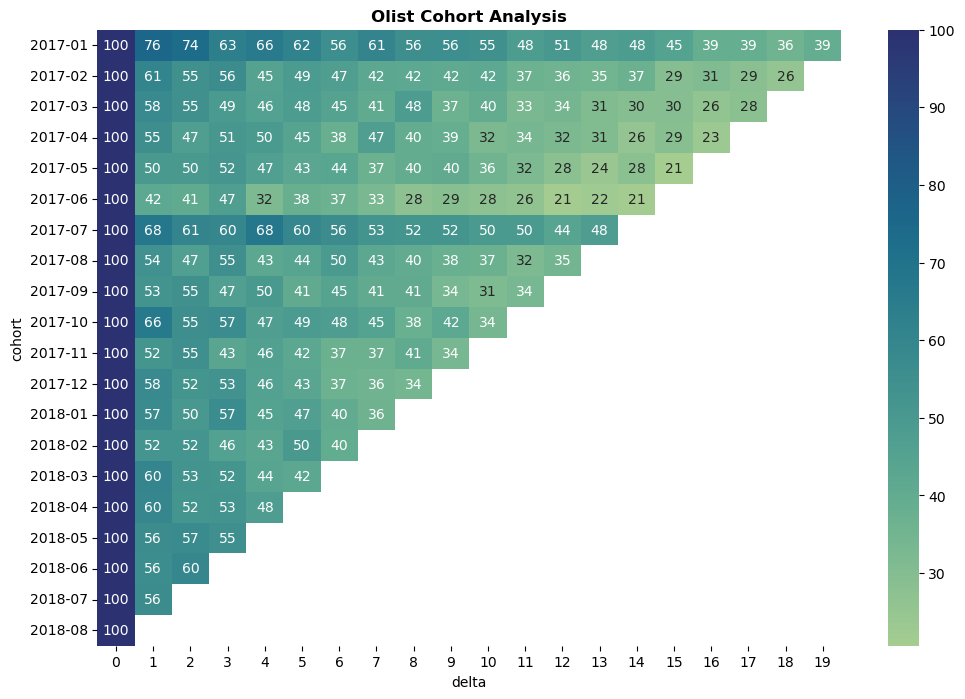

In [208]:
plt.figure(figsize=(12,8))
sns.heatmap(
    cohort_pivot,
    cmap='crest', #type de couleur
    annot=True, #intégrer le pourcentage dans chaque case
    fmt='.0f') #permet de tout mettre en entier
plt.title('Olist Cohort Analysis',fontweight='bold');

###  9. Que déduire de cette visualisation ?

## BONUS : Différents types de segmentation (exercice ouvert)

**_Contexte_**

Olist est très satisfait de ton travail, et veut que tu ailles plus loin. Ils voudraient que tu **effectues une analyse par segments de toutes leurs données 2016-2018**.

Avec cette analyse supplémentaire, ils espérent que tu **identifies d'autres groupes et d'autres métriques pertinentes à analyser**, et que tu en tires des **recommendations business fondées sur des la visualisation des données**.

---

**_Données_**

Les données à utiliser sont accessibles sur Kaggle : [link](https://www.kaggle.com/olistbr/brazilian-ecommerce) ou sur la plateforme Databird. Les 8 tables de données 'opérationnelles' sont exploitables.

---

**_Mission_**

Pour effectuer cette analyse Bonus, concentre-toi sur **un autre type de segmentation** puis essaie de **construire quelques graphiques intéressants** pour formuler des **recommendations**. N'oublie pas si besoin de nettoyer les données que tu utilises (valeurs manquantes, types de variables, etc.).

__Tu peux choisir l'une des segmentations ci-dessous (la liste n'est pas exhaustive)__:

* **Rétention**: s'intéresser aux clients qui ont réalisé plusieurs commandes. Les métriques à observer (KPI) peuvent être : le délai entre deux commandes, la valeur/taille des commandes, les produits favoris, la catégorie de produits favorite, etc.
<br><br>
* **Client size**: créer des groupes de clients selon la valeur de leurs commandes, ou selon le volume de biens commandés. Ensuite, essayer de voir si ces groupes ont des caractéristiques différentes, par exemple les moyens de paiement, la catégorie de produits favorite, l'origine géographique, etc.
<br><br>
* **Récence**: regrouper les clients selon leur date de dernier achat. On peut considérer que les clients actifs sont ceux qui ont passé une commande dans les 6 derniers mois, les inactifs entre 6 et 12 mois, et les clients perdus ("lost") n'ont pas passé de commande depius plus de 12 mois. Essayer d'identifier les caractéristiques propres à chacun de ces groupes (valeur des commandes, quantités commandées, etc.).
<br><br>
* **Préférences**: étudier les consommateurs par groupes selon les catégories de produits qu'ils préfèrent, et regarder comment évoluent les quantités commandées, l'orgine géographique, etc.
<br><br>
* **Seller-side**: comme dans le use case précédent, cette segmentation concerne les vendeurs, mais les regroupe de façon différente ; par exemple par nombre de produits vendus. On peut ensuite analyser les caractéristiques des vendeurs qui ont les meilleures performances, etc.

### 1. Pre-processing

Commencez par exécuter les cellules ci-dessous pour charger les données, fusionner les tables et effectuer toutes les étapes de pre-processing.

_Note :_ Ci-dessous, les données sont lues directement sur GitHub pour éviter le téléchargement (vous pouvez cependant les télécharger et utiliser vos propres fichiers). La fonction `clean_olist` rédigée par Thomas de Mareuil permet de réaliser le pre-processing en une seule ligne (vous pouvez cependant tester chaque étape du pre-processing de votre côté, ce qui pourrait déjà être un bon exercice en soi). Attention, même avec la fonction il reste toujours quelques imperfections sur lesquelles vous pourrez vous pencher :)

In [217]:
customers = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/olist_customers_dataset.csv')
items = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/olist_order_items_dataset.csv')
payments = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/olist_order_payments_dataset.csv')
reviews = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/olist_order_reviews_dataset.csv')
orders = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/olist_orders_dataset.csv')
products = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/olist_products_dataset.csv')
sellers = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/olist_sellers_dataset.csv')
names = pd.read_csv('https://raw.githubusercontent.com/dujiaying/olist/master/data/product_category_name_translation.csv')

In [210]:
def clean_olist(customers,
                items,
                payments,
                reviews,
                orders,
                products,
                sellers,
                names,
                merge_all=True):
    """
    Takes as input the different operational Olist tables and outputs
    a unique dataframe (almost) ready for cohort analysis.
    If merge_all = False, outputs 4 dataframes, to be merged manually.
    """
    
    # merge dataframes
    merged = items.merge(products, on='product_id', how='outer')\
                   .merge(sellers, on='seller_id', how='outer')\
                   .merge(orders, on='order_id', how='outer')\
                   .merge(payments, on='order_id', how='outer')\
                   .merge(reviews, on='order_id', how='outer')\
                   .merge(customers, on='customer_id', how='outer')
    
    # drop irrelevant columns for our analysis
    merged = merged.drop(columns=['payment_sequential', #'payment_type', 'payment_installments', # unhelpful data
                            'customer_id', # random id per order, not interesting
                            'customer_zip_code_prefix', 'customer_city', 'seller_zip_code_prefix', 'seller_city', # redundant data
                            'review_id', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', # text is too complex to analyse here
                            'order_approved_at', 'order_delivered_carrier_date', 'shipping_limit_date', # unhelpful data
                            'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', # unhelpful data
                            ])
    
    # compute delivery delay
    merged['delivery_delay'] = pd.to_datetime(merged.order_delivered_customer_date) - pd.to_datetime(merged.order_estimated_delivery_date)
    merged['delivery_delay'] = merged['delivery_delay'].dt.round('d')
    merged = merged.drop(columns = ['order_delivered_customer_date', 'order_estimated_delivery_date'])
    
    # count quantity of each product per order, using order_item_id
    quantity_table = merged[['order_id', 'order_item_id']].groupby('order_id').max().reset_index()
    quantity_table.columns = ['order_id', 'order_item_quantity']
    merged = merged.merge(quantity_table, on='order_id', how='outer')

    # drop payment duplicates
    merged = merged.drop_duplicates(subset=['order_id','payment_value'])

    # count payment installments
    installments_table = merged[['order_id', 'payment_installments']].groupby('order_id').max().reset_index()
    installments_table.columns = ['order_id', 'payment_instalments']
    merged = merged.merge(installments_table, on='order_id', how='outer')

    # count payment types
    types_table = merged[['order_id', 'payment_type']].groupby('order_id').nunique().reset_index()
    types_table.columns = ['order_id', 'payment_types']
    merged = merged.merge(types_table, on='order_id', how='outer')

    # sum payment value
    payment_table = merged[['order_id', 'payment_value']].groupby('order_id').sum().reset_index()
    payment_table.columns = ['order_id', 'total_payment_value']
    merged = merged.merge(payment_table, on='order_id', how='outer')

    # drop order + product duplicates
    merged = merged.drop_duplicates(subset=['order_id', 'product_id'])

    # drop old columns
    merged = merged.drop(columns=['order_item_id', 'payment_type', 'payment_installments', 'payment_value'])
    
    # compute price per item per order
    merged['order_item_value'] = merged.order_item_quantity * (merged.price + merged.freight_value)
    
    # drop some missing values
    merged = merged[~merged['product_id'].isna()].reset_index(drop=True)
    
    # add country to state codes
    merged.customer_state = merged.customer_state.apply(lambda x: 'BR-' + x)
    merged.seller_state = merged.seller_state.apply(lambda x: 'BR-' + x)

    # convert timestamps to datetime
    #merged.order_purchase_timestamp = pd.to_datetime(merged.order_purchase_timestamp)
    # left incorrect type on purpose
    
    # translate product category names
    portuguese = list(list(names.to_dict().values())[0].values())
    english = list(list(names.to_dict().values())[1].values())
    language_pairs = {k:v for k,v in zip(portuguese, english)}
    language_pairs['nan'] = np.nan
    language_pairs['pc_gamer'] = 'pc_gamer'
    language_pairs['portateis_cozinha_e_preparadores_de_alimentos'] = 'portable_kitchen_food_preparers'
    merged['product_category_name'] = merged['product_category_name'].apply(lambda x: language_pairs[str(x)])

    if merge_all:
        return merged[['order_id', 'customer_unique_id', 'seller_id', 'product_id', 'product_category_name',
                     'price', 'freight_value', 'order_item_quantity', 'order_item_value', 
                     'total_payment_value', 'payment_types', 'payment_instalments', 'review_score',
                     'order_purchase_timestamp', 'order_status', 'delivery_delay',
                     'customer_state', 'seller_state']]

    else:
        # split dataframe in 4
        orders_info = merged[['order_id', 'customer_unique_id', 'seller_id', 'product_id',
                     'price', 'freight_value', 'order_item_quantity', 'order_item_value', 
                     'total_payment_value', 'payment_types', 'payment_instalments', 'review_score',
                     'order_purchase_timestamp', 'order_status', 'delivery_delay']]
        customers_info = merged[['customer_unique_id', 'customer_state']]
        sellers_info = merged[['seller_id', 'seller_state']]
        product_info = merged[['product_id', 'product_category_name']]
        return (orders_info, product_info, customers_info, sellers_info)

In [218]:
merged = clean_olist(customers,
                     items,
                     payments,
                     reviews,
                     orders,
                     products,
                     sellers,
                     names)

In [219]:
merged.head()

,order_id,customer_unique_id,seller_id,product_id,product_category_name,price,freight_value,order_item_quantity,order_item_value,total_payment_value,payment_types,payment_instalments,review_score,order_purchase_timestamp,order_status,delivery_delay,customer_state,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,48436dade18ac8b2bce089ec2a041202,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90,13.29,1.0,72.19,72.19,1,2.0,5,2017-09-13 08:59:02,delivered,-8 days,BR-RJ,BR-SP
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,dd7ddc04e1b6c2c614352b383efe2d36,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90,19.93,1.0,259.83,259.83,1,3.0,4,2017-04-26 10:53:06,delivered,-2 days,BR-SP,BR-SP
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,5b51032eddd242adc84c38acab88f23d,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.00,17.87,1.0,216.87,216.87,1,5.0,5,2018-01-14 14:33:31,delivered,-13 days,BR-MG,BR-MG
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,9d7a1d34a5052409006425275ba1c2b4,7634da152a4610f1595efa32f14722fc,perfumery,12.99,12.79,1.0,25.78,25.78,1,2.0,4,2018-08-08 10:00:35,delivered,-5 days,BR-SP,BR-SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,df560393f3a51e74553ab94004ba5c87,ac6c3623068f30de03045865e4e10089,garden_tools,199.90,18.14,1.0,218.04,218.04,1,3.0,5,2017-02-04 13:57:51,delivered,-15 days,BR-SP,BR-PR


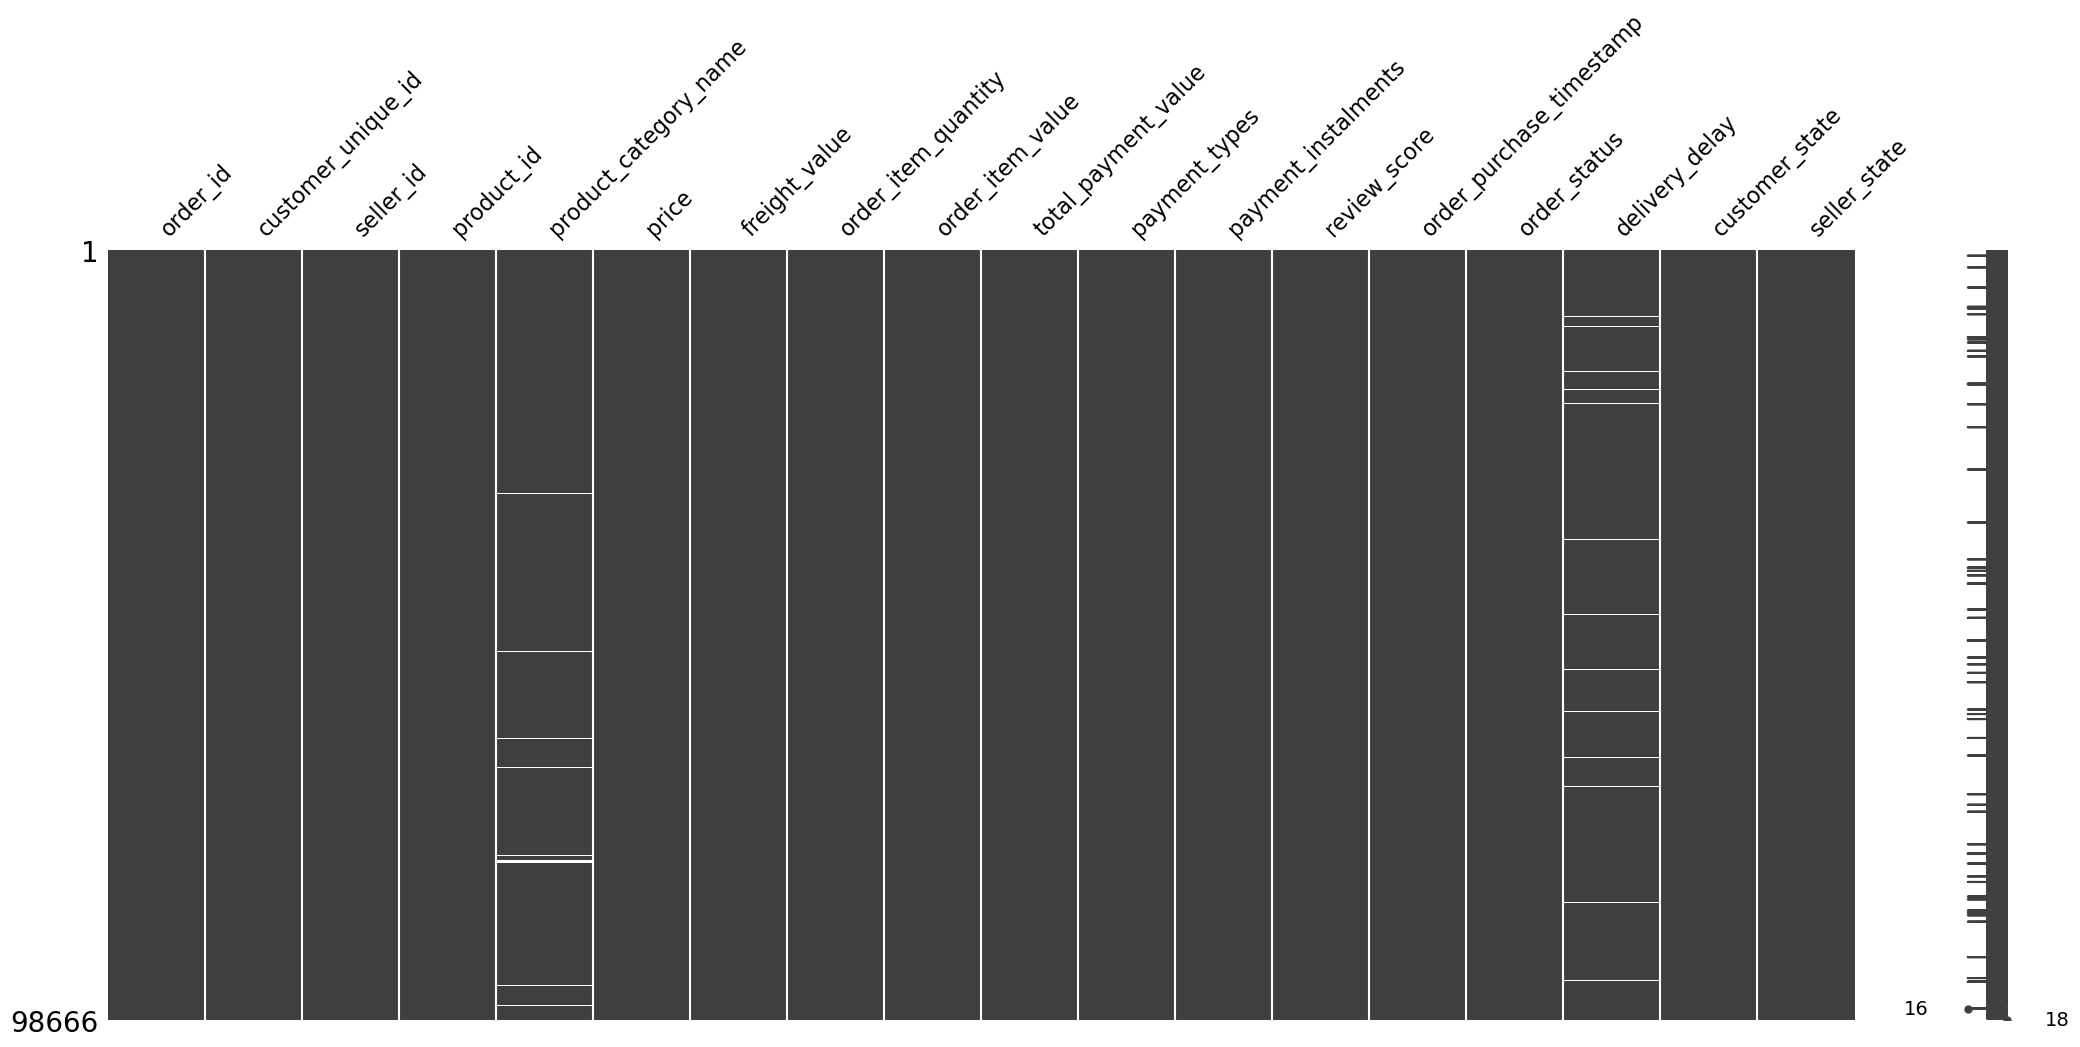

In [213]:
import missingno as msno
msno.matrix(merged);

In [214]:
merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98666 entries, 0 to 98665
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype          
---  ------                    --------------  -----          
 0   order_id                  98666 non-null  object         
 1   customer_unique_id        98666 non-null  object         
 2   seller_id                 98666 non-null  object         
 3   product_id                98666 non-null  object         
 4   product_category_name     97253 non-null  object         
 5   price                     98666 non-null  float64        
 6   freight_value             98666 non-null  float64        
 7   order_item_quantity       98666 non-null  float64        
 8   order_item_value          98666 non-null  float64        
 9   total_payment_value       98666 non-null  float64        
 10  payment_types             98666 non-null  int64          
 11  payment_instalments       98665 non-null  float64        
 12  revi

In [215]:
merged.to_csv('clean_olist.csv', index=False)

### 2. Segmentation analysis

$\rightarrow$ The floor is yours!